# SwinV2 — Swin Transformer V2

**Paper:** Z. Liu, H. Hu, Y. Lin, Z. Yao, Z. Wei, S. Ning, Y. Cao, Z. Zhang, L. Dong, F. Wei, and B. Guo,
"Swin Transformer V2: Scaling Up Capacity and Resolution," in *Proc. IEEE/CVF CVPR*, 2022, pp. 12009–12019.
arXiv: [2111.09883](https://arxiv.org/abs/2111.09883)

> **One-line summary:** A hierarchical window-attention transformer with three
> scaling-friendly upgrades — residual post-norm, log-CPB position bias, and
> scaled cosine attention — enabling models up to 3 billion parameters trained
> on images up to 1536×1536.


> 📄 **Paper:** Liu et al. (2022). Swin Transformer V2: Scaling Up Capacity and Resolution. CVPR 2022.
> 🔗 **Link:** <https://arxiv.org/abs/2111.09883>
> 🧩 **Implementation:** `hale_core/nn/vision/swin/swinv2.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> PE["patch partition 4×4 + linear embed → 96"]:::stage
  PE --> S1["stage 1 ×2 (96) /4"]:::stage --> M1["patch merging /2 ×2C"]:::block --> S2["stage 2 ×2 (192) /8"]:::stage
  S2 --> M2["merge"]:::block --> S3["stage 3 ×6 (384) /16"]:::stage --> M3["merge"]:::block --> S4["stage 4 ×2 (768) /32"]:::stage --> GAP["LN · avg pool"]:::block --> OUT
  subgraph BLK["Swin V2 block pair (W-MSA then SW-MSA)"]
    direction LR
    X["x"] --> WA["window attention<br/>cosine(q, k)/τ + log-CPB bias"]:::block --> PN1["post-norm LN"]:::block --> A1(("+"))
    X --> A1 --> MLP["MLP"]:::block --> PN2["post-norm LN"]:::block --> A2(("+"))
    A1 --> A2
    A2 -->|"shift windows by M/2"| WA
  end
  S1 -.-> BLK
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Pipeline (ASCII)

```
Input Image [B, 3, H, W]
        │
        ▼
┌─────────────────────┐
│   Patch Embedding   │  4×4 stride Conv → Linear projection
│   [B, H/4, W/4, C] │
└──────────┬──────────┘
           │
     ┌─────▼──────┐
     │   Stage 0  │  depth=2,  output [B, H/4,  W/4,  C]
     │  W-MSA + SW-MSA blocks  │
     └─────┬──────┘
           │  Patch Merge (2C)
     ┌─────▼──────┐
     │   Stage 1  │  depth=2,  output [B, H/8,  W/8,  2C]
     └─────┬──────┘
           │  Patch Merge (4C)
     ┌─────▼──────┐
     │   Stage 2  │  depth=6–42, output [B, H/16, W/16, 4C]
     └─────┬──────┘
           │  Patch Merge (8C)
     ┌─────▼──────┐
     │   Stage 3  │  depth=2,  output [B, H/32, W/32, 8C]
     └─────┬──────┘
           │
    Global Avg Pool
           │
    pooled_output [B, 8C]

─────────────────────────────────────────
 Single SwinV2 Block Detail
─────────────────────────────────────────

  x [B, H, W, C]
       │
  [Cyclic Shift by win//2] ← only shifted blocks
       │
  Window Partition → [B*nW, win², C]
       │
  Scaled Cosine Attention
    Q, K, V = Linear(x)
    A = cos(Q,K) / τ  +  LogCPB(Δrow, Δcol)
    out = softmax(A) · V
       │
  Window Reverse
       │
  [Reverse Cyclic Shift] ← only shifted blocks
       │
  Residual: x = LN(x + attn_out)   ← Post-Norm
       │
  FFN: Linear(4C)→GELU→Linear(C)
       │
  Residual: x = LN(x + ffn_out)    ← Post-Norm
```


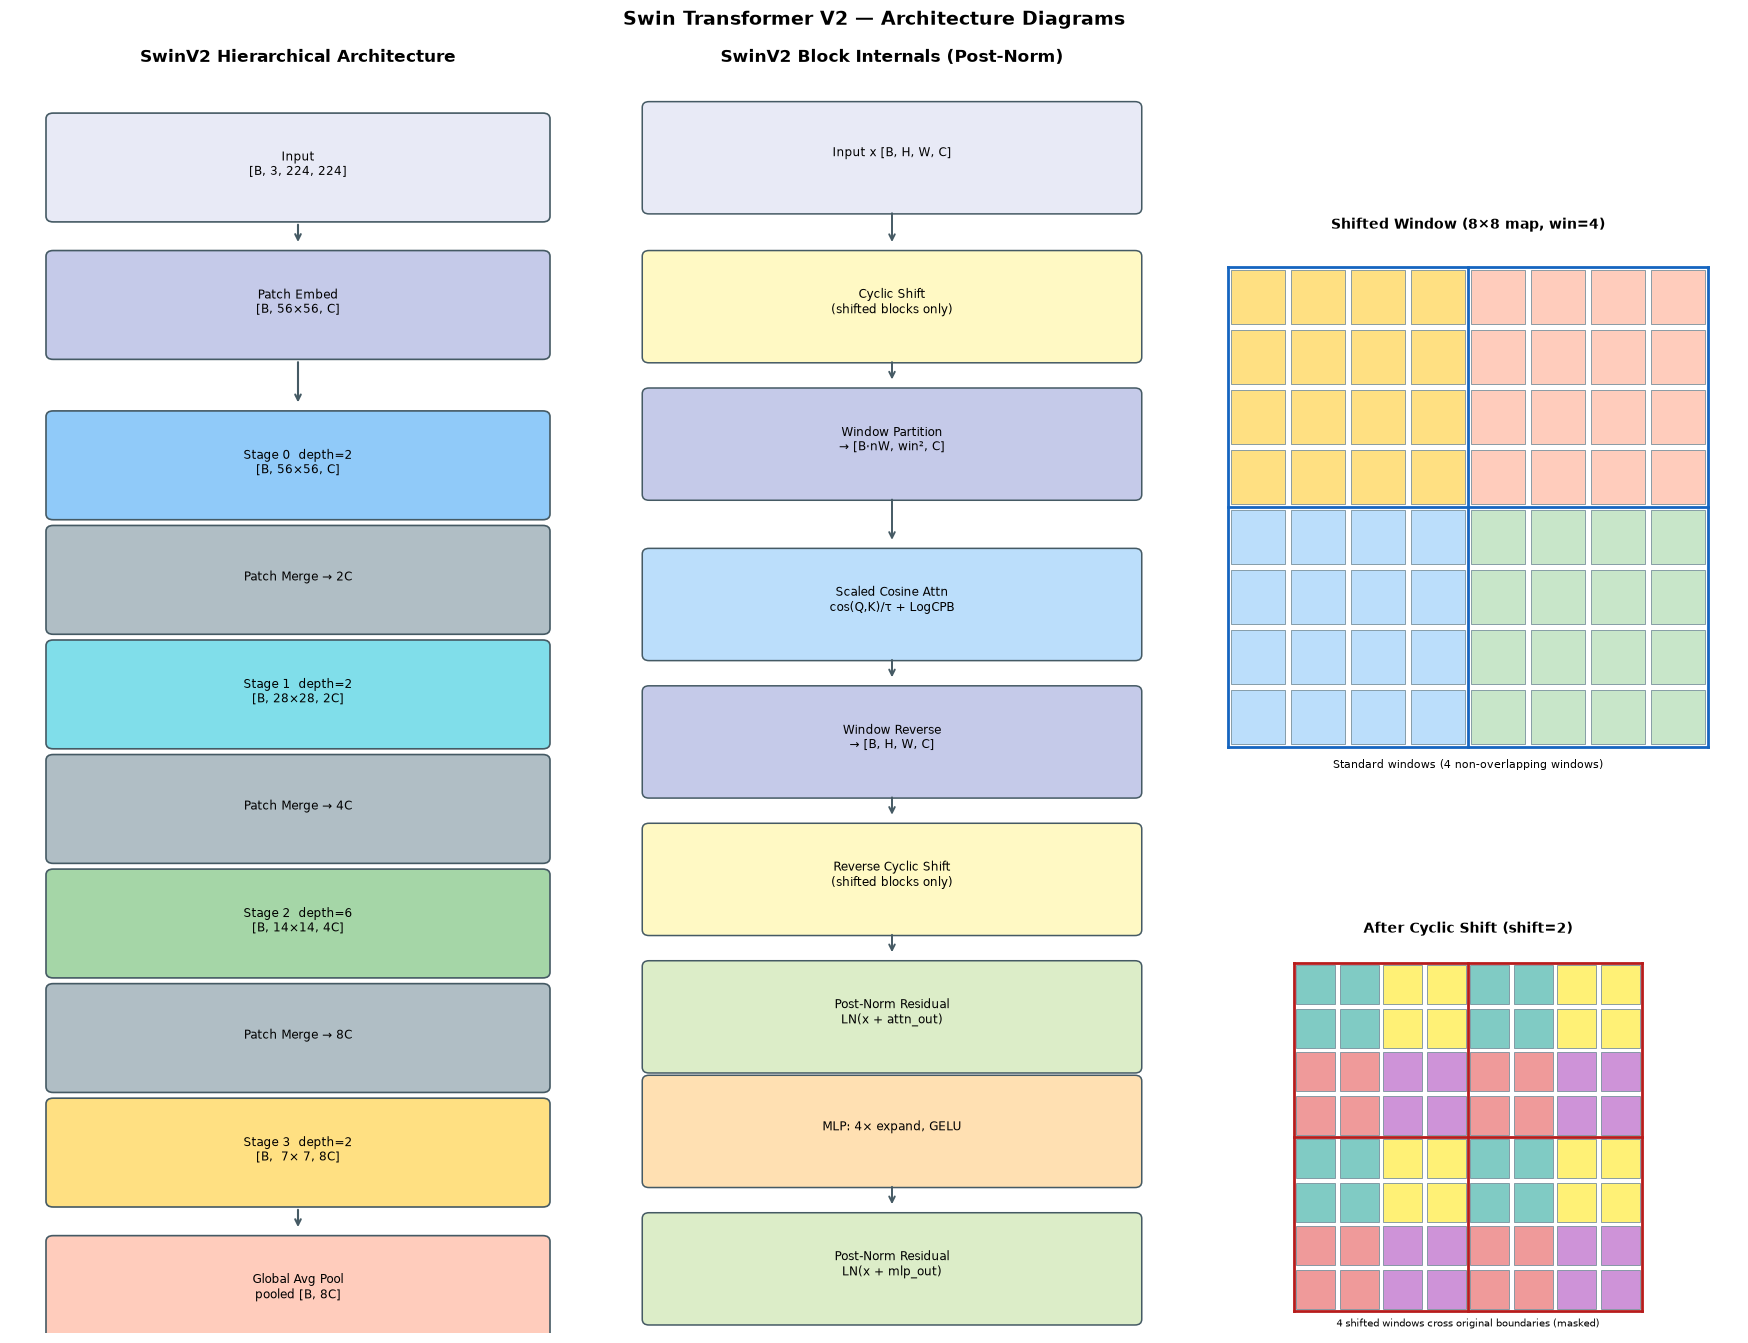

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import numpy as np

fig = plt.figure(figsize=(18, 14))

# ── Left panel: model-level hierarchy ──────────────────────────────────────
ax1 = fig.add_axes([0.02, 0.05, 0.32, 0.90])
ax1.set_xlim(0, 4)
ax1.set_ylim(0, 11)
ax1.axis('off')
ax1.set_title('SwinV2 Hierarchical Architecture', fontsize=12, fontweight='bold', pad=8)

stages = [
    ('Input\n[B, 3, 224, 224]',    10.2, '#e8eaf6'),
    ('Patch Embed\n[B, 56×56, C]', 9.0,  '#c5cae9'),
    ('Stage 0  depth=2\n[B, 56×56, C]',  7.6,  '#90caf9'),
    ('Patch Merge → 2C',            6.6,  '#b0bec5'),
    ('Stage 1  depth=2\n[B, 28×28, 2C]', 5.6,  '#80deea'),
    ('Patch Merge → 4C',            4.6,  '#b0bec5'),
    ('Stage 2  depth=6\n[B, 14×14, 4C]', 3.6,  '#a5d6a7'),
    ('Patch Merge → 8C',            2.6,  '#b0bec5'),
    ('Stage 3  depth=2\n[B,  7× 7, 8C]', 1.6,  '#ffe082'),
    ('Global Avg Pool\npooled [B, 8C]',  0.4,  '#ffccbc'),
]

for label, y, color in stages:
    box = FancyBboxPatch((0.3, y - 0.45), 3.4, 0.85,
                         boxstyle='round,pad=0.05', facecolor=color, edgecolor='#455a64', linewidth=1.2)
    ax1.add_patch(box)
    ax1.text(2.0, y, label, ha='center', va='center', fontsize=8.5)

for i in range(len(stages) - 1):
    y1 = stages[i][1] - 0.5
    y2 = stages[i+1][1] + 0.5
    ax1.annotate('', xy=(2.0, y2), xytext=(2.0, y1),
                 arrowprops=dict(arrowstyle='->', color='#455a64', lw=1.5))

# ── Middle panel: block internals ──────────────────────────────────────────
ax2 = fig.add_axes([0.36, 0.05, 0.30, 0.90])
ax2.set_xlim(0, 4)
ax2.set_ylim(0, 11)
ax2.axis('off')
ax2.set_title('SwinV2 Block Internals (Post-Norm)', fontsize=12, fontweight='bold', pad=8)

block_steps = [
    ('Input x [B, H, W, C]', 10.3, '#e8eaf6'),
    ('Cyclic Shift\n(shifted blocks only)', 9.0, '#fff9c4'),
    ('Window Partition\n→ [B·nW, win², C]', 7.8, '#c5cae9'),
    ('Scaled Cosine Attn\ncos(Q,K)/τ + LogCPB', 6.4, '#bbdefb'),
    ('Window Reverse\n→ [B, H, W, C]', 5.2, '#c5cae9'),
    ('Reverse Cyclic Shift\n(shifted blocks only)', 4.0, '#fff9c4'),
    ('Post-Norm Residual\nLN(x + attn_out)', 2.8, '#dcedc8'),
    ('MLP: 4× expand, GELU', 1.8, '#ffe0b2'),
    ('Post-Norm Residual\nLN(x + mlp_out)', 0.6, '#dcedc8'),
]

for label, y, color in block_steps:
    box = FancyBboxPatch((0.2, y - 0.48), 3.6, 0.88,
                         boxstyle='round,pad=0.05', facecolor=color, edgecolor='#455a64', linewidth=1.1)
    ax2.add_patch(box)
    ax2.text(2.0, y, label, ha='center', va='center', fontsize=8.5)

for i in range(len(block_steps) - 1):
    y1 = block_steps[i][1] - 0.5
    y2 = block_steps[i+1][1] + 0.5
    ax2.annotate('', xy=(2.0, y2), xytext=(2.0, y1),
                 arrowprops=dict(arrowstyle='->', color='#455a64', lw=1.4))

# ── Right panel: window shifting visualisation ──────────────────────────────
ax3 = fig.add_axes([0.68, 0.35, 0.30, 0.58])
ax3.set_xlim(-0.5, 8.5)
ax3.set_ylim(-0.5, 8.5)
ax3.set_aspect('equal')
ax3.set_title('Shifted Window (8×8 map, win=4)', fontsize=10, fontweight='bold')
ax3.axis('off')

grid_colors_orig = [
    '#bbdefb', '#bbdefb', '#bbdefb', '#bbdefb', '#c8e6c9', '#c8e6c9', '#c8e6c9', '#c8e6c9',
    '#bbdefb', '#bbdefb', '#bbdefb', '#bbdefb', '#c8e6c9', '#c8e6c9', '#c8e6c9', '#c8e6c9',
    '#bbdefb', '#bbdefb', '#bbdefb', '#bbdefb', '#c8e6c9', '#c8e6c9', '#c8e6c9', '#c8e6c9',
    '#bbdefb', '#bbdefb', '#bbdefb', '#bbdefb', '#c8e6c9', '#c8e6c9', '#c8e6c9', '#c8e6c9',
    '#ffe082', '#ffe082', '#ffe082', '#ffe082', '#ffccbc', '#ffccbc', '#ffccbc', '#ffccbc',
    '#ffe082', '#ffe082', '#ffe082', '#ffe082', '#ffccbc', '#ffccbc', '#ffccbc', '#ffccbc',
    '#ffe082', '#ffe082', '#ffe082', '#ffe082', '#ffccbc', '#ffccbc', '#ffccbc', '#ffccbc',
    '#ffe082', '#ffe082', '#ffe082', '#ffe082', '#ffccbc', '#ffccbc', '#ffccbc', '#ffccbc',
]
for row in range(8):
    for col in range(8):
        idx = row * 8 + col
        rect = mpatches.FancyBboxPatch((col + 0.05, row + 0.05), 0.9, 0.9,
                                       boxstyle='square,pad=0.0',
                                       facecolor=grid_colors_orig[idx],
                                       edgecolor='#78909c', linewidth=0.6)
        ax3.add_patch(rect)

for i in range(0, 9, 4):
    ax3.plot([i, i], [0, 8], color='#1565c0', lw=2.0)
    ax3.plot([0, 8], [i, i], color='#1565c0', lw=2.0)

ax3.text(4.0, -0.35, 'Standard windows (4 non-overlapping windows)', ha='center', fontsize=8)

# Shifted window panel
ax4 = fig.add_axes([0.68, 0.05, 0.30, 0.28])
ax4.set_xlim(-0.5, 8.5)
ax4.set_ylim(-0.5, 8.5)
ax4.set_aspect('equal')
ax4.set_title('After Cyclic Shift (shift=2)', fontsize=10, fontweight='bold')
ax4.axis('off')

shift_colors = [
    '#ef9a9a', '#ef9a9a', '#ce93d8', '#ce93d8', '#ef9a9a', '#ef9a9a', '#ce93d8', '#ce93d8',
    '#ef9a9a', '#ef9a9a', '#ce93d8', '#ce93d8', '#ef9a9a', '#ef9a9a', '#ce93d8', '#ce93d8',
    '#80cbc4', '#80cbc4', '#fff176', '#fff176', '#80cbc4', '#80cbc4', '#fff176', '#fff176',
    '#80cbc4', '#80cbc4', '#fff176', '#fff176', '#80cbc4', '#80cbc4', '#fff176', '#fff176',
    '#ef9a9a', '#ef9a9a', '#ce93d8', '#ce93d8', '#ef9a9a', '#ef9a9a', '#ce93d8', '#ce93d8',
    '#ef9a9a', '#ef9a9a', '#ce93d8', '#ce93d8', '#ef9a9a', '#ef9a9a', '#ce93d8', '#ce93d8',
    '#80cbc4', '#80cbc4', '#fff176', '#fff176', '#80cbc4', '#80cbc4', '#fff176', '#fff176',
    '#80cbc4', '#80cbc4', '#fff176', '#fff176', '#80cbc4', '#80cbc4', '#fff176', '#fff176',
]
for row in range(8):
    for col in range(8):
        idx = row * 8 + col
        rect = mpatches.FancyBboxPatch((col + 0.05, row + 0.05), 0.9, 0.9,
                                       boxstyle='square,pad=0.0',
                                       facecolor=shift_colors[idx],
                                       edgecolor='#78909c', linewidth=0.6)
        ax4.add_patch(rect)

for i in range(0, 9, 4):
    ax4.plot([i, i], [0, 8], color='#b71c1c', lw=2.0)
    ax4.plot([0, 8], [i, i], color='#b71c1c', lw=2.0)

ax4.text(4.0, -0.35, '4 shifted windows cross original boundaries (masked)', ha='center', fontsize=7.5)

plt.suptitle('Swin Transformer V2 — Architecture Diagrams', fontsize=14, fontweight='bold', y=0.995)

plt.show()

## 3. Key ideas

## Key Innovations (SwinV1 → SwinV2)

### 1. Residual Post-Norm

**SwinV1 (pre-norm):**
$$x' = x + \text{Attn}(\text{LN}(x))$$
$$x'' = x' + \text{FFN}(\text{LN}(x'))$$

**SwinV2 (post-norm):**
$$x' = \text{LN}\bigl(x + \text{Attn}(x)\bigr)$$
$$x'' = \text{LN}\bigl(x' + \text{FFN}(x')\bigr)$$

*Why it matters:* In very deep networks (e.g. 48-layer SwinV2-G), pre-norm causes
activation magnitudes to grow with depth, making training unstable.
Post-norm normalises after each residual, keeping magnitudes controlled throughout.

---

### 2. Log-Continuous Position Bias (Log-CPB)

**SwinV1** learned a fixed position-bias *table* of shape
$[(2 \cdot \text{win} - 1)^2,\ \text{heads}]$.
This table is tied to the training window size — changing the window at
inference requires discarding or interpolating learned biases.

**SwinV2** replaces the table with a tiny MLP:

$$\hat{\Delta} = \text{sign}(\Delta)\cdot\log_{}(1 + |\Delta|)$$
$$B(\Delta_r, \Delta_c) = 16\cdot\sigma\!\left(\text{MLP}(\hat{\Delta}_r,\, \hat{\Delta}_c)\right)$$

The MLP is a 2-layer network $\mathbb{R}^2 \to \mathbb{R}^{512} \to \mathbb{R}^{\text{heads}}$.
Because the MLP takes *continuous* log-space coordinates rather than discrete integers,
it generalises smoothly to unseen window sizes at inference.

---

### 3. Scaled Cosine Attention

**Standard dot-product:**
$$A_{ij} = \frac{\mathbf{q}_i^\top \mathbf{k}_j}{\sqrt{d}} + B_{ij}$$

**SwinV2 scaled cosine:**
$$A_{ij} = \frac{\cos(\mathbf{q}_i, \mathbf{k}_j)}{\tau} + B_{ij}$$

where $\tau = \exp(\log \hat{\tau})$ is a *learnable per-head temperature*,
initialised to $\log(10)$.

*Why cosine?*  In large models, dot-product magnitudes grow with embedding dimension,
leading to peaked (low-entropy) attention distributions — a small number of tokens
dominate. Cosine similarity is normalised to $[-1, 1]$, and $\tau$ provides a
tunable sharpness independent of dimension scale.

---

### 4. Shifted Window Attention Mask

After cyclic shift by $(\text{win}//2,\ \text{win}//2)$, each window may contain
tokens from **up to 4 different** original windows. An attention mask
$M \in \{0, -\infty\}^{\text{win}^2 \times \text{win}^2}$ is added
before softmax so tokens from different original regions cannot attend to each other:

$$M_{ij} = \begin{cases} 0 & \text{if region}(i) = \text{region}(j) \\ -100 & \text{otherwise} \end{cases}$$

This preserves the intended local receptive field while enabling cross-window
connections in the NEXT block (which will not be shifted).


## Code Walkthrough

### Log-CPB MLP (registry path: `hale_core.nn.vision.swin.swinv2.LogContinuousPositionBias`)

```python
class LogContinuousPositionBias(nn.Module):
    def __init__(self, num_heads):
        self.cpb_mlp = nn.Sequential(
            nn.Linear(2, 512, bias=True),
            nn.ReLU(inplace=True),
            nn.Linear(512, num_heads, bias=False),
        )

    def _compute_bias(self, window_size):
        coords_h = torch.arange(window_size)
        coords_w = torch.arange(window_size)
        coords = torch.stack(torch.meshgrid(coords_h, coords_w, indexing='ij'))
        coords_flat = coords.flatten(1)              # [2, win*win]
        rel = coords_flat[:, :, None] - coords_flat[:, None, :]
        rel = rel.permute(1, 2, 0).float()           # [win², win², 2]

        # Log-compress: sign(d)·log(1+|d|) keeps values in ≈[-3.2, 3.2]
        rel_log = rel.sign() * torch.log1p(rel.abs())
        rel_log = rel_log / math.log(window_size) * 8.0   # normalise

        bias = 16.0 * self.cpb_mlp(rel_log).sigmoid()     # [win², win², heads]
        return bias.permute(2, 0, 1)                       # [heads, win², win²]
```

### Scaled Cosine Attention (`SwinV2WindowAttention.forward`)

```python
def forward(self, x, mask=None):
    B, N, C = x.shape
    qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim)
    q, k, v = qkv.permute(2, 0, 3, 1, 4).unbind(0)   # [B, heads, N, d]

    # Normalise to unit sphere, then scale by learnable temperature
    q = F.normalize(q, dim=-1)
    k = F.normalize(k, dim=-1)
    tau = self.logit_scale.exp().clamp(max=math.log(100))
    attn = (q @ k.transpose(-2, -1)) * tau             # cosine / tau

    # Add Log-CPB relative position bias
    bias = self.cpb(self.window_size)                  # [heads, win², win²]
    attn = attn + bias.unsqueeze(0)

    # Shifted-window mask: adds -100 to blocked token pairs
    if mask is not None:
        attn = attn + mask.unsqueeze(1)
    ...
```

### Patch Merging

```python
class PatchMerging(nn.Module):
    # Doubles channels while halving resolution (like a strided pooling)
    def forward(self, x):                 # x: [B, H, W, C]
        x0 = x[:, 0::2, 0::2, :]         # top-left
        x1 = x[:, 1::2, 0::2, :]         # bottom-left
        x2 = x[:, 0::2, 1::2, :]         # top-right
        x3 = x[:, 1::2, 1::2, :]         # bottom-right
        x = torch.cat([x0, x1, x2, x3], dim=-1)   # [B, H/2, W/2, 4C]
        return self.proj(self.norm(x))             # → [B, H/2, W/2, 2C]
```

### Model Variants

| Name | Window | Channels C | Depths | Params |
|------|--------|-----------|--------|--------|
| swinv2_tiny | 8 | 96 | [2,2,6,2] | ~28 M |
| swinv2_small | 8 | 96 | [2,2,18,2] | ~50 M |
| swinv2_base | 8 | 128 | [2,2,18,2] | ~88 M |
| swinv2_large | 16 | 192 | [2,2,18,2] | ~197 M |
| swinv2_giant | 16 | 192 | [2,2,42,2] | ~3 B |


## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/swin/swinv2.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>swin/swinv2.py</code></summary>

```text
SwinV2 — Swin Transformer V2 (Liu et al., 2022)
================================================

Reference: "Swin Transformer V2: Scaling Up Capacity and Resolution"
           https://arxiv.org/abs/2111.09883

Architecture overview
---------------------
SwinV2 is a hierarchical vision transformer that operates on shifted windows,
making it efficient for high-resolution inputs. It introduces three key upgrades
over SwinV1 to enable scaling to billions of parameters and gigapixel images:

1. **Residual Post-Norm** (instead of pre-norm):
   LayerNorm is applied AFTER the residual addition. This stabilises gradient
   flow in very deep networks and allows training with larger models.

2. **Log-spaced Continuous Relative Position Bias (Log-CPB)**:
   Instead of a learnable table indexed by integer offsets (which is fixed to
   the training window size), Log-CPB uses a small MLP that maps log-compressed
   (dx, dy) differences to a bias scalar. This allows fine-tuning at window
   sizes different from pretraining without discarding learned position info.
       log_cpb(dx, dy) = MLP(sign(dx)·log(1+|dx|), sign(dy)·log(1+|dy|))

3. **Scaled Cosine Attention**:
   Instead of dot-product attention, uses:
       attn(Q, K) = cos(Q, K) / tau + B
   where tau is a learnable log-scale per-head temperature (init=log(10)),
   preventing attention logit explosion in very deep models.

Window mechanics
----------------
- Input [B, H, W, C] is partitioned into (H//win) × (W//win) windows of size win×win.
- Self-attention runs independently inside each window (local receptive field).
- For SHIFTED windows, the feature map is cyclically shifted by (win//2, win//2)
  before partitioning, then un-shifted after. An attention mask prevents tokens
  in different "regions" from attending to each other across the shift boundary.

Multi-scale hierarchy
---------------------
Stage 0: patch embed (4×4 stride) → 2 blocks,         output H/4  × W/4  × C
Stage 1: patch merge (2×2 stride) → 2..42 blocks,     output H/8  × W/8  × 2C
Stage 2: patch merge              → N blocks,          output H/16 × W/16 × 4C
Stage 3: patch merge              → 2..4 blocks,       output H/32 × W/32 × 8C

BackboneOutput
--------------
  pooled_output  : [B, 8C]           — global average of stage-3 features
  feature_maps   : [[B,C,H/4,W/4], [B,2C,H/8,W/8], [B,4C,H/16,W/16], [B,8C,H/32,W/32]]
  patch_tokens   : None              — not meaningful for SwinV2 (spatial, not seq)
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `swin/swinv2.py`, definition by definition

In [5]:
def _trunc_normal_(tensor: torch.Tensor, std: float = 0.02) -> torch.Tensor:
    """Truncated normal initialization (values clipped to ±2σ)."""
    with torch.no_grad():
        return tensor.normal_(0, std).clamp_(-2 * std, 2 * std)

In [6]:
def window_partition(x: torch.Tensor, window_size: int) -> torch.Tensor:
    """Partition spatial feature map into non-overlapping windows.

    Args:
        x:           [B, H, W, C]
        window_size: Window height == width

    Returns:
        windows: [num_windows*B, window_size, window_size, C]
    """
    B, H, W, C = x.shape
    x = x.view(B, H // window_size, window_size, W // window_size, window_size, C)
    # Reorder to [B, nH, nW, win, win, C] → [B*nH*nW, win, win, C]
    windows = x.permute(0, 1, 3, 2, 4, 5).contiguous()
    return windows.view(-1, window_size, window_size, C)

In [7]:
def window_reverse(
    windows: torch.Tensor, window_size: int, H: int, W: int
) -> torch.Tensor:
    """Reconstruct feature map from windows.

    Args:
        windows:     [num_windows*B, window_size, window_size, C]
        window_size: Window height == width
        H, W:        Original spatial dimensions

    Returns:
        x: [B, H, W, C]
    """
    B = int(windows.shape[0] / (H * W / window_size / window_size))
    x = windows.view(B, H // window_size, W // window_size, window_size, window_size, -1)
    x = x.permute(0, 1, 3, 2, 4, 5).contiguous().view(B, H, W, -1)
    return x

**`LogContinuousPositionBias`** - Log-spaced Continuous Position Bias (Log-CPB) for SwinV2.

In [8]:
class LogContinuousPositionBias(nn.Module):
    """Log-spaced Continuous Position Bias (Log-CPB) for SwinV2.

    Replaces the fixed learnable table of SwinV1 with a small MLP that inputs
    log-compressed coordinate differences. This allows inference at resolutions
    different from training (the MLP generalises; a table does not).

    The MLP maps (2,) → (num_heads,) via two linear layers.
    """

    def __init__(self, num_heads: int) -> None:
        super().__init__()
        self.num_heads = num_heads
        # Small MLP: 2 → 512 → num_heads (no bias on last layer for stability)
        self.cpb_mlp = nn.Sequential(
            nn.Linear(2, 512, bias=True),
            nn.ReLU(inplace=True),
            nn.Linear(512, num_heads, bias=False),
        )

    def _compute_bias(self, window_size: int) -> torch.Tensor:
        """Compute relative position bias for a given window size.

        Returns:
            bias: [num_heads, window_size*window_size, window_size*window_size]
        """
        coords_h = torch.arange(window_size, device=next(self.parameters()).device)
        coords_w = torch.arange(window_size, device=next(self.parameters()).device)
        # All pairwise (row, col) differences
        coords = torch.stack(torch.meshgrid(coords_h, coords_w, indexing="ij"))  # [2, win, win]
        coords_flat = coords.flatten(1)  # [2, win*win]
        # Relative distances: [2, win*win, win*win]
        rel = coords_flat[:, :, None] - coords_flat[:, None, :]
        rel = rel.permute(1, 2, 0).float()  # [win*win, win*win, 2]

        # Log-compress: sign(d) * log(1 + |d|)  — values in ≈ [-3.2, 3.2] for win=8
        rel_log = rel.sign() * torch.log1p(rel.abs())

        # Normalise to [-8, 8] so MLP sees consistent scale regardless of window_size
        norm_factor = math.log(window_size)
        rel_log = rel_log / norm_factor * 8.0

        # MLP → [win*win, win*win, num_heads]
        bias = self.cpb_mlp(rel_log)
        # Apply sigmoid to keep magnitudes bounded → scale to [-log(max_dist), log(max_dist)]
        bias = 16.0 * bias.sigmoid()
        # Rearrange to [num_heads, win*win, win*win]
        bias = bias.permute(2, 0, 1).contiguous()
        return bias

    def forward(self, window_size: int) -> torch.Tensor:
        """Return the relative position bias for ``window_size``, recomputed on every call.

        The bias must not be cached: it is a function of the trainable ``cpb_mlp``. A cached
        tensor either has no autograd graph (if first computed under ``no_grad`` / in eval, so
        the MLP never trains) or a graph that is freed after the first ``backward()`` (so the
        second training step fails), and it goes stale after every optimiser step or
        ``load_state_dict``. The MLP runs on only window² × window² coordinate pairs.
        """
        return self._compute_bias(window_size)

**`SwinV2WindowAttention`** - Scaled cosine self-attention within a single window.

In [9]:
class SwinV2WindowAttention(nn.Module):
    """Scaled cosine self-attention within a single window.

    SwinV2 change: replaces dot-product Q·K^T with cosine similarity / tau
    to prevent logit explosion in large models.

    Args:
        dim:         Input channel count.
        window_size: Window height == width.
        num_heads:   Number of attention heads.
        attn_drop:   Dropout on attention weights.
        proj_drop:   Dropout on output projection.
    """

    def __init__(
        self,
        dim: int,
        window_size: int,
        num_heads: int,
        attn_drop: float = 0.0,
        proj_drop: float = 0.0,
    ) -> None:
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.window_size = window_size

        # Q, K, V projection (all-in-one for efficiency)
        self.qkv = nn.Linear(dim, dim * 3, bias=True)
        self.proj = nn.Linear(dim, dim)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj_drop = nn.Dropout(proj_drop)

        # Log-CPB for resolution-agnostic relative position bias
        self.rel_pos_bias = LogContinuousPositionBias(num_heads)

        # Learnable per-head log-scale temperature (init=log(10) ≈ 2.30)
        # tau = exp(logit_scale.clip(max=log(100))) to prevent collapse
        self.logit_scale = nn.Parameter(torch.full((num_heads, 1, 1), math.log(10.0)))

    def forward(
        self, x: torch.Tensor, mask: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        """
        Args:
            x:    [B*num_windows, win*win, C]
            mask: [num_windows, win*win, win*win] or None
        Returns:
            out: [B*num_windows, win*win, C]
        """
        Bw, N, C = x.shape
        # Compute Q, K, V
        qkv = self.qkv(x).reshape(Bw, N, 3, self.num_heads, self.head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)  # [3, Bw, heads, N, head_dim]
        q, k, v = qkv.unbind(0)

        # Normalise Q and K to unit length for cosine similarity
        q = F.normalize(q, dim=-1)
        k = F.normalize(k, dim=-1)

        # Temperature-scaled cosine attention
        tau = torch.clamp(self.logit_scale, max=math.log(100.0)).exp()
        attn = (q @ k.transpose(-2, -1)) * tau  # [Bw, heads, N, N]

        # Add Log-CPB relative position bias
        rpb = self.rel_pos_bias(self.window_size)  # [heads, N, N]
        attn = attn + rpb.unsqueeze(0)

        # Shifted-window attention mask: additive −∞ for cross-region pairs
        if mask is not None:
            nW = mask.shape[0]
            attn = attn.view(Bw // nW, nW, self.num_heads, N, N)
            attn = attn + mask.unsqueeze(1).unsqueeze(0)
            attn = attn.view(-1, self.num_heads, N, N)

        attn = self.attn_drop(F.softmax(attn, dim=-1))
        out = (attn @ v).transpose(1, 2).reshape(Bw, N, C)
        return self.proj_drop(self.proj(out))

**`SwinV2Block`** - A single SwinV2 transformer block with post-norm.

In [10]:
class SwinV2Block(nn.Module):
    """A single SwinV2 transformer block with post-norm.

    Two variants controlled by `shift`:
      shift=False → standard window attention
      shift=True  → shifted window attention (cross-window context)

    SwinV2 change: LayerNorm is placed AFTER the residual connection
    (post-norm) instead of before (pre-norm). This improves gradient flow.

    Args:
        dim:         Channel dimension.
        num_heads:   Attention heads.
        window_size: Window spatial size.
        shift:       Whether to use shifted window attention.
        mlp_ratio:   FFN hidden dim ratio (default 4×).
        drop:        Dropout rate.
        attn_drop:   Attention dropout.
        drop_path:   Stochastic depth drop rate.
    """

    def __init__(
        self,
        dim: int,
        num_heads: int,
        window_size: int,
        shift: bool = False,
        mlp_ratio: float = 4.0,
        drop: float = 0.0,
        attn_drop: float = 0.0,
        drop_path: float = 0.0,
    ) -> None:
        super().__init__()
        self.window_size = window_size
        self.shift_size = window_size // 2 if shift else 0

        self.attn = SwinV2WindowAttention(
            dim, window_size, num_heads, attn_drop=attn_drop, proj_drop=drop
        )
        mlp_hidden = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(
            nn.Linear(dim, mlp_hidden),
            nn.GELU(),
            nn.Dropout(drop),
            nn.Linear(mlp_hidden, dim),
            nn.Dropout(drop),
        )
        # Post-norm (SwinV2 change: norm goes AFTER residual, not before)
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)

        # Stochastic depth: drop entire residual branch with probability drop_path
        self.drop_path = DropPath(drop_path) if drop_path > 0 else nn.Identity()

        # Cached shifted-window attention mask (computed once per H,W)
        self._attn_mask: Optional[torch.Tensor] = None
        self._mask_hw: Optional[tuple] = None

    def _get_attn_mask(self, H: int, W: int, device: torch.device) -> Optional[torch.Tensor]:
        """Compute or retrieve cached attention mask for shifted windows.

        The mask ensures shifted-window tokens only attend within their
        original (pre-shift) window region — prevents cross-region mixing.

        Returns None for non-shifted blocks (no mask needed).
        """
        if self.shift_size == 0:
            return None
        if self._mask_hw == (H, W):
            return self._attn_mask

        # Label each window region with an integer ID
        img_mask = torch.zeros((1, H, W, 1), device=device)
        slices_h = (
            slice(0, -self.window_size),
            slice(-self.window_size, -self.shift_size),
            slice(-self.shift_size, None),
        )
        slices_w = (
            slice(0, -self.window_size),
            slice(-self.window_size, -self.shift_size),
            slice(-self.shift_size, None),
        )
        cnt = 0
        for sh in slices_h:
            for sw in slices_w:
                img_mask[:, sh, sw, :] = cnt
                cnt += 1

        mask_windows = window_partition(img_mask, self.window_size)  # [nW, win, win, 1]
        mask_windows = mask_windows.view(-1, self.window_size * self.window_size)
        # Tokens with different region IDs should NOT attend to each other
        attn_mask = mask_windows.unsqueeze(1) - mask_windows.unsqueeze(2)
        attn_mask = attn_mask.masked_fill(attn_mask != 0, -100.0).masked_fill(attn_mask == 0, 0.0)

        self._attn_mask = attn_mask
        self._mask_hw = (H, W)
        return attn_mask

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: [B, H, W, C]
        Returns:
            x: [B, H, W, C]
        """
        B, H, W, C = x.shape

        # Pad to the nearest multiple of window_size so partition never sees a
        # remainder.  The padding is stripped before the residual connection so
        # the output always has the original H, W.
        pad_h = (self.window_size - H % self.window_size) % self.window_size
        pad_w = (self.window_size - W % self.window_size) % self.window_size
        x_in = F.pad(x, (0, 0, 0, pad_w, 0, pad_h)) if (pad_h or pad_w) else x
        Hp, Wp = H + pad_h, W + pad_w

        # Cyclic shift for shifted-window variant
        if self.shift_size > 0:
            shifted = torch.roll(x_in, shifts=(-self.shift_size, -self.shift_size), dims=(1, 2))
        else:
            shifted = x_in

        # Partition into windows → [B*nW, win*win, C]
        win_x = window_partition(shifted, self.window_size)
        win_x = win_x.view(-1, self.window_size * self.window_size, C)

        # Window attention (mask is built for the padded Hp×Wp grid)
        mask = self._get_attn_mask(Hp, Wp, x.device)
        attn_out = self.attn(win_x, mask=mask)

        # Reconstruct spatial layout
        attn_out = attn_out.view(-1, self.window_size, self.window_size, C)
        shifted = window_reverse(attn_out, self.window_size, Hp, Wp)

        # Reverse cyclic shift
        if self.shift_size > 0:
            shifted = torch.roll(shifted, shifts=(self.shift_size, self.shift_size), dims=(1, 2))

        # Strip padding before residual so shapes match the original x
        if pad_h or pad_w:
            shifted = shifted[:, :H, :W, :].contiguous()

        # Post-norm residual (SwinV2 change)
        x = self.norm1(x + self.drop_path(shifted))

        # FFN with post-norm residual
        x = self.norm2(x + self.drop_path(self.mlp(x)))
        return x

**`DropPath`** - Stochastic depth: drop entire residual branch per-sample during training.

In [11]:
class DropPath(nn.Module):
    """Stochastic depth: drop entire residual branch per-sample during training.

    At inference (eval mode) acts as identity.  The remaining branches are
    scaled up by 1/(1-p) so expected value is preserved (like Dropout).

    Args:
        drop_prob: Probability of dropping a branch in a given step.
    """

    def __init__(self, drop_prob: float = 0.0) -> None:
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training or self.drop_prob == 0.0:
            return x
        keep_prob = 1.0 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        noise = torch.rand(shape, dtype=x.dtype, device=x.device).floor_() + keep_prob
        return x.div(keep_prob) * noise

**`PatchEmbed`** - 4×4 non-overlapping patch projection (stem).

In [12]:
class PatchEmbed(nn.Module):
    """4×4 non-overlapping patch projection (stem).

    Converts [B, 3, H, W] → [B, H/4, W/4, embed_dim].
    Uses a single Conv2d(kernel=4, stride=4) followed by LayerNorm.
    """

    def __init__(self, in_chans: int = 3, embed_dim: int = 96) -> None:
        super().__init__()
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=4, stride=4)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: [B, C, H, W] → [B, H/4, W/4, embed_dim]"""
        x = self.proj(x)           # [B, embed_dim, H/4, W/4]
        x = x.permute(0, 2, 3, 1) # [B, H/4, W/4, embed_dim] — channels-last
        return self.norm(x)

**`PatchMerging`** - Downsample by 2× and double channels: H×W×C → H/2×W/2×2C.

In [13]:
class PatchMerging(nn.Module):
    """Downsample by 2× and double channels: H×W×C → H/2×W/2×2C.

    Takes 2×2 spatial neighbours, concatenates channel-wise (→ 4C),
    applies LayerNorm, then projects 4C → 2C with a linear layer.
    """

    def __init__(self, dim: int) -> None:
        super().__init__()
        self.norm = nn.LayerNorm(4 * dim)
        self.reduction = nn.Linear(4 * dim, 2 * dim, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: [B, H, W, C] → [B, H/2, W/2, 2C]"""
        B, H, W, C = x.shape
        # Sample every-other pixel in both spatial dimensions
        x0 = x[:, 0::2, 0::2, :]  # top-left
        x1 = x[:, 1::2, 0::2, :]  # bottom-left
        x2 = x[:, 0::2, 1::2, :]  # top-right
        x3 = x[:, 1::2, 1::2, :]  # bottom-right
        x = torch.cat([x0, x1, x2, x3], dim=-1)  # [B, H/2, W/2, 4C]
        return self.reduction(self.norm(x))

**`SwinV2Stage`** - One stage: optional PatchMerging + N SwinV2 blocks.

In [14]:
class SwinV2Stage(nn.Module):
    """One stage: optional PatchMerging + N SwinV2 blocks.

    Blocks alternate between regular (shift=False) and shifted (shift=True)
    window attention to capture both local and cross-window context.

    Args:
        dim:          Input channel count.
        depth:        Number of transformer blocks.
        num_heads:    Attention heads.
        window_size:  Window spatial size.
        downsample:   Whether to prepend a PatchMerging layer.
        drop_path_rates: List of stochastic-depth rates per block.
    """

    def __init__(
        self,
        dim: int,
        depth: int,
        num_heads: int,
        window_size: int,
        downsample: bool = True,
        drop_path_rates: Optional[list] = None,
    ) -> None:
        super().__init__()
        # Optional spatial downsampling at the beginning of each stage
        self.downsample = PatchMerging(dim // 2) if downsample else nn.Identity()
        # Output dim after optional merge
        out_dim = dim if downsample else dim

        rates = drop_path_rates or [0.0] * depth
        self.blocks = nn.ModuleList([
            SwinV2Block(
                dim=out_dim,
                num_heads=num_heads,
                window_size=window_size,
                shift=(i % 2 == 1),  # Alternate: even=regular, odd=shifted
                drop_path=rates[i],
            )
            for i in range(depth)
        ])

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: [B, H, W, C] → [B, H', W', C'] (C' doubled if downsample)"""
        x = self.downsample(x)
        for blk in self.blocks:
            x = blk(x)
        return x

**`SwinV2Backbone`** - SwinV2 vision backbone.

In [15]:
class SwinV2Backbone(BaseVisionBackbone):
    """SwinV2 vision backbone.

    Args:
        embed_dim:   Channel count after stem (stage 0 has this dim).
        depths:      Number of blocks per stage, e.g. [2, 2, 6, 2].
        num_heads:   Attention heads per stage, e.g. [3, 6, 12, 24].
        window_size: Local attention window size (default 8 for 224px, 12 for 384px).
        drop_path_rate: Total stochastic depth rate (linearly distributed over blocks).
        **base_kwargs: Passed to BaseVisionBackbone (img_size, in_chans, etc.)
    """

    def __init__(
        self,
        embed_dim: int = 96,
        depths: list = None,
        num_heads: list = None,
        window_size: int = 8,
        drop_path_rate: float = 0.2,
        **base_kwargs,
    ) -> None:
        super().__init__(**base_kwargs)
        depths = depths or [2, 2, 6, 2]
        num_heads = num_heads or [3, 6, 12, 24]

        # Set class-level attributes used by base class __repr__
        self.__class__.feature_dims = [embed_dim * (2 ** i) for i in range(len(depths))]
        self.__class__.embed_dim = embed_dim * (2 ** (len(depths) - 1))

        # Distribute stochastic depth linearly over all blocks
        total_blocks = sum(depths)
        dp_rates = [
            x.item() for x in torch.linspace(0, drop_path_rate, total_blocks)
        ]

        # Stem: 4×4 patch projection
        self.patch_embed = PatchEmbed(self.in_chans, embed_dim)

        # 4 stages
        block_idx = 0
        self.stages = nn.ModuleList()
        for i, (depth, heads) in enumerate(zip(depths, num_heads)):
            stage_rates = dp_rates[block_idx: block_idx + depth]
            block_idx += depth
            self.stages.append(
                SwinV2Stage(
                    dim=embed_dim * (2 ** i),       # Current stage's channel count
                    depth=depth,
                    num_heads=heads,
                    window_size=window_size,
                    downsample=(i > 0),             # No downsample at stage 0 (patch embed does it)
                    drop_path_rates=stage_rates,
                )
            )

        self.norm = nn.LayerNorm(self.embed_dim)
        self.drop = nn.Dropout(self.drop_rate)

        self._init_weights()

    def _init_weights(self) -> None:
        """Truncated normal init for all linear/conv layers."""
        for m in self.modules():
            if isinstance(m, (nn.Linear, nn.Conv2d)):
                _trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.LayerNorm):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze patch embed + stages 0..stage (inclusive)."""
        for p in self.patch_embed.parameters():
            p.requires_grad_(False)
        for i in range(min(stage + 1, len(self.stages))):
            for p in self.stages[i].parameters():
                p.requires_grad_(False)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """
        Args:
            x: [B, 3, H, W]
        Returns:
            BackboneOutput with pooled_output and 4-scale feature_maps
        """
        # Stem: [B, 3, H, W] → [B, H/4, W/4, C]
        x = self.patch_embed(x)

        feature_maps = []
        for stage in self.stages:
            x = stage(x)
            # Convert channels-last → channels-first for feature_maps convention
            fm = x.permute(0, 3, 1, 2).contiguous()  # [B, C, H, W]
            feature_maps.append(fm)

        # Final norm on last stage features
        x = self.norm(x)

        # Global average pool over spatial dims for pooled embedding
        pooled = x.mean(dim=(1, 2))  # [B, C]
        pooled = self.drop(pooled)

        # Filter by out_indices if specified
        if self.out_indices is not None:
            feature_maps = [feature_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,          # SwinV2 is spatial, not sequential
            feature_maps=feature_maps,
        )

**`SwinV2Tiny`** - SwinV2-Tiny: 28M params. Fast, suitable for mobile / edge.

In [16]:
@register_vision_backbone("swinv2_tiny")
class SwinV2Tiny(SwinV2Backbone):
    """SwinV2-Tiny: 28M params. Fast, suitable for mobile / edge."""
    arch_name = "swinv2_tiny"
    embed_dim = 768   # 96 * 8

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 96)
        kwargs.setdefault("depths", [2, 2, 6, 2])
        kwargs.setdefault("num_heads", [3, 6, 12, 24])
        kwargs.setdefault("window_size", 8)
        super().__init__(**kwargs)

**`SwinV2Small`** - SwinV2-Small: 50M params. Good balance of accuracy/speed.

In [17]:
@register_vision_backbone("swinv2_small")
class SwinV2Small(SwinV2Backbone):
    """SwinV2-Small: 50M params. Good balance of accuracy/speed."""
    arch_name = "swinv2_small"
    embed_dim = 768

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 96)
        kwargs.setdefault("depths", [2, 2, 18, 2])
        kwargs.setdefault("num_heads", [3, 6, 12, 24])
        kwargs.setdefault("window_size", 8)
        super().__init__(**kwargs)

**`SwinV2Base`** - SwinV2-Base: 88M params. High accuracy, used in many benchmarks.

In [18]:
@register_vision_backbone("swinv2_base")
class SwinV2Base(SwinV2Backbone):
    """SwinV2-Base: 88M params. High accuracy, used in many benchmarks."""
    arch_name = "swinv2_base"
    embed_dim = 1024

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 128)
        kwargs.setdefault("depths", [2, 2, 18, 2])
        kwargs.setdefault("num_heads", [4, 8, 16, 32])
        kwargs.setdefault("window_size", 8)
        super().__init__(**kwargs)

**`SwinV2Large`** - SwinV2-Large: 197M params. Strong ImageNet-22K pretrain.

In [19]:
@register_vision_backbone("swinv2_large")
class SwinV2Large(SwinV2Backbone):
    """SwinV2-Large: 197M params. Strong ImageNet-22K pretrain."""
    arch_name = "swinv2_large"
    embed_dim = 1536

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 192)
        kwargs.setdefault("depths", [2, 2, 18, 2])
        kwargs.setdefault("num_heads", [6, 12, 24, 48])
        kwargs.setdefault("window_size", 12)
        super().__init__(**kwargs)

**`SwinV2Giant`** - SwinV2-Giant: 3B params. Highest accuracy in the SwinV2 family.

In [20]:
@register_vision_backbone("swinv2_giant")
class SwinV2Giant(SwinV2Backbone):
    """SwinV2-Giant: 3B params. Highest accuracy in the SwinV2 family."""
    arch_name = "swinv2_giant"
    embed_dim = 1536

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 192)
        kwargs.setdefault("depths", [2, 2, 42, 4])
        kwargs.setdefault("num_heads", [6, 12, 24, 48])
        kwargs.setdefault("window_size", 12)
        super().__init__(**kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [21]:
DEMOS = {'swinv2_tiny': 28.3}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['swinv2_base', 'swinv2_giant', 'swinv2_large', 'swinv2_small', 'swinv2_tiny']



swinv2_tiny  (SwinV2Tiny)
  pooled_output : (2, 768)   embed_dim = 768
  feature_map 0: (2, 96, 56, 56)   stride 4
  feature_map 1: (2, 192, 28, 28)   stride 8
  feature_map 2: (2, 384, 14, 14)   stride 16
  feature_map 3: (2, 768, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [22]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
swinv2_tiny              27.59M     28.35M    28.3M    1.00  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [23]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

swinv2_tiny: loss 4.0547 | 207/207 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [24]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

swinv2_tiny: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

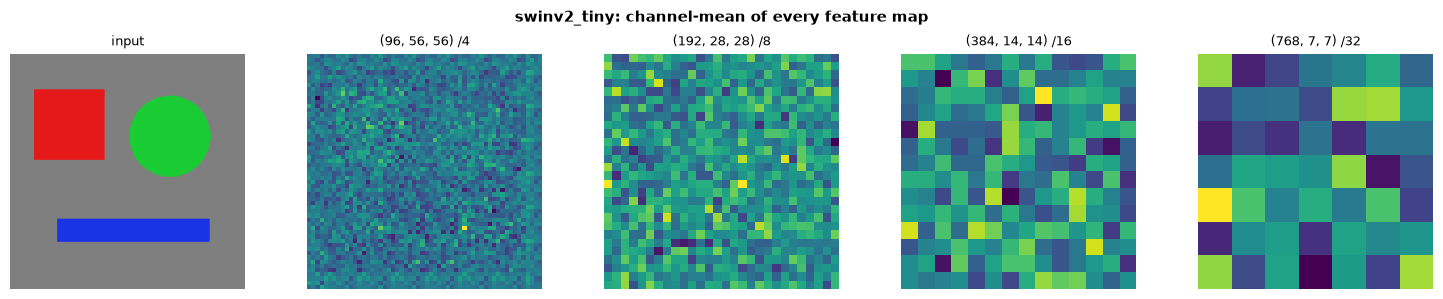

In [25]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [26]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [27]:
import sys
import torch

# ── Build SwinV2-Tiny and trace shapes through stages ──────────────────────
backbone = build_vision_backbone('swinv2_tiny', img_size=224)
backbone.eval()

print(f'Model: swinv2_tiny')
print(f'Parameters: {backbone.num_parameters():,}')
print(f'Embed dim:  {backbone.embed_dim}')
print()

# Register hooks to print intermediate shapes
shapes = {}
def make_hook(name):
    def hook(module, inp, out):
        if isinstance(out, torch.Tensor):
            shapes[name] = tuple(out.shape)
    return hook

backbone.patch_embed.register_forward_hook(make_hook('patch_embed'))
for i, stage in enumerate(backbone.stages):
    stage.register_forward_hook(make_hook(f'stage_{i}'))

x = torch.randn(1, 3, 224, 224)
with torch.no_grad():
    out = backbone(x)

print('Shape trace (channels-last, HaleBlocks uses channels-first in feature_maps):')
for name, shape in shapes.items():
    print(f'  {name:15s} → {shape}')
print()
print('BackboneOutput:')
print(f'  pooled_output : {tuple(out.pooled_output.shape)}')
print(f'  feature_maps  : {[tuple(fm.shape) for fm in out.feature_maps]}')
print(f'  patch_tokens  : {out.patch_tokens}')

# Test freeze API
backbone.freeze_up_to_stage(1)
trainable = backbone.num_parameters(trainable_only=True)
total    = backbone.num_parameters()
print(f'\nAfter freeze_up_to_stage(1):')
print(f'  Trainable: {trainable:,} / {total:,}  ({100*trainable/total:.1f}%)')

Model: swinv2_tiny
Parameters: 27,585,258
Embed dim:  768

Shape trace (channels-last, HaleBlocks uses channels-first in feature_maps):
  patch_embed     → (1, 56, 56, 96)
  stage_0         → (1, 56, 56, 96)
  stage_1         → (1, 28, 28, 192)
  stage_2         → (1, 14, 14, 384)
  stage_3         → (1, 7, 7, 768)

BackboneOutput:
  pooled_output : (1, 768)
  feature_maps  : [(1, 96, 56, 56), (1, 192, 28, 28), (1, 384, 14, 14), (1, 768, 7, 7)]
  patch_tokens  : None

After freeze_up_to_stage(1):
  Trainable: 26,377,080 / 27,585,258  (95.6%)


## Paper Citation & Related Work

### Primary Reference

> Z. Liu, H. Hu, Y. Lin, Z. Yao, Z. Wei, S. Ning, Y. Cao, Z. Zhang, L. Dong, F. Wei, and B. Guo,
> "Swin Transformer V2: Scaling Up Capacity and Resolution,"
> in *Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)*,
> 2022, pp. 12009–12019.
> **arXiv:** https://arxiv.org/abs/2111.09883

### SwinV1 (predecessor)

> Z. Liu, Y. Lin, Y. Cao, H. Hu, Y. Wei, Z. Zhang, S. Lin, and B. Guo,
> "Swin Transformer: Hierarchical Vision Transformer using Shifted Windows,"
> in *ICCV*, 2021. arXiv: 2103.14030

### Related Architectures

| Model | Key Idea | Reference |
|-------|----------|----------|
| ViT | Global patch self-attention | Dosovitskiy et al., ICLR 2021 |
| Twins | Alternative to shifted windows using PVT-style pooling | Chu et al., NeurIPS 2021 |
| CSWin | Cross-shaped window attention | Dong et al., CVPR 2022 |
| FocalTransformer | Focal attention (local fine + global coarse) | Yang et al., NeurIPS 2021 |
| MaxViT | Block + grid attention (this repo) | Tu et al., ECCV 2022 |

### Key Ablations from Paper

- Residual post-norm: +0.1 ImageNet top-1, critical for 3B-param stability
- Log-CPB vs. bicubic interpolation of SwinV1 table: +0.3 top-1 at different resolutions
- Scaled cosine vs. dot-product: +0.5 top-1 for SwinV2-G
- SwinV2-G achieves **90.17%** top-1 on ImageNet-1K (224px), **63.1** box AP on COCO
